In [1]:
import sys
from pathlib import Path

# SAGE is not installed in this kernel: put the SAGE repo (the folder that holds sage/) on the path
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sage" / "__init__.py").exists()), None)
print(root)
if root is None:
    raise RuntimeError("SAGE repo not found above " + str(Path.cwd()) + ": run the notebook from inside it")
sys.path.insert(0, str(root))

import torch
from gwpy.timeseries import TimeSeries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sage.data.noise import sample_synthetic_noise
from sage.dsp.qtransform import QTransform
from sage.dsp import decimate
from sage.dsp.welch import TorchWelch
from sage.dsp.whiten import FIRWhitening


/home/melissa.lopez/sage


/cvmfs/software.igwn.org/conda/envs/igwn-py311/lib/python3.11/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [ ]:
start, end = df['GPStime'].iloc[0] - 20, df['GPStime'].iloc[0] + 20

def generate_data(start, end, fs, highpass=15):
    # Load data
    data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')
    
    data_torch = torch.tensor(data.value)

    # Resample
    fs_old = int(data.sample_rate.value) # 16 kHz -> 4 kHz
    x_sage = decimate(data_torch, fs_old // fs)   # half-band FIR anti-alias, x2 per pass

    # Compute ASD
    f_sage, psd_sage = TorchWelch(delta_t=1 / fs, seg_len=4 * fs, seg_stride=2 * fs)(x_sage, return_freqs=True)                         # frequencies (Hz) and PSD
    asd_sage = psd_sage.sqrt()

    # Whiten
    white_sage = FIRWhitening(fs, highpass=highpass, dtype=torch.float64)whiten(x_sage.reshape(1, 1, -1), asd_sage[None])[0, 0]             # 1 s shorter at each end
    cut = dc * fs - whiten.pad                                                       # then the same crop as gwpy: start + dc to end - dc
    white_sage = white_sage[cut:white_sage.numel() - cut]

In [27]:
whiten.pad 

4096

In [2]:
file = 'O3b_vigilant_train_set.csv'
df = pd.read_csv(file)
len(df['GPStime'])

11193

In [3]:
start, end = df['GPStime'].iloc[0] - 20, df['GPStime'].iloc[0] + 20
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

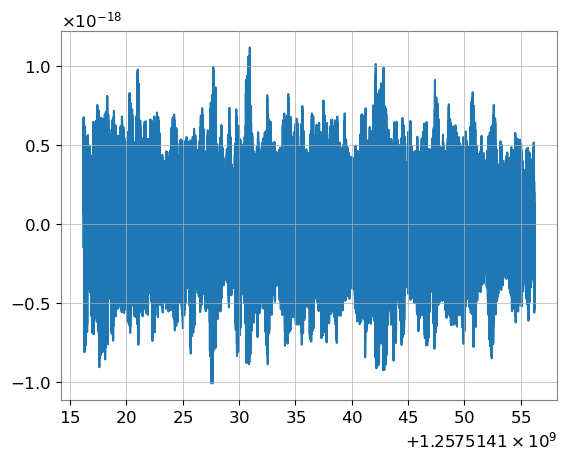

In [4]:
plt.plot(data)

In [7]:
fs, dt, dc = 4096, 32, 16
t0 = df['GPStime'].iloc[0]
start, end = df['GPStime'].iloc[0] - dt, df['GPStime'].iloc[0] + dt
data = TimeSeries.get('V1:Hrec_hoft_16384Hz', start, end, frametype='HoftOnline')

32.0 s
CPU times: user 543 ms, sys: 13.6 ms, total: 556 ms
Wall time: 559 ms


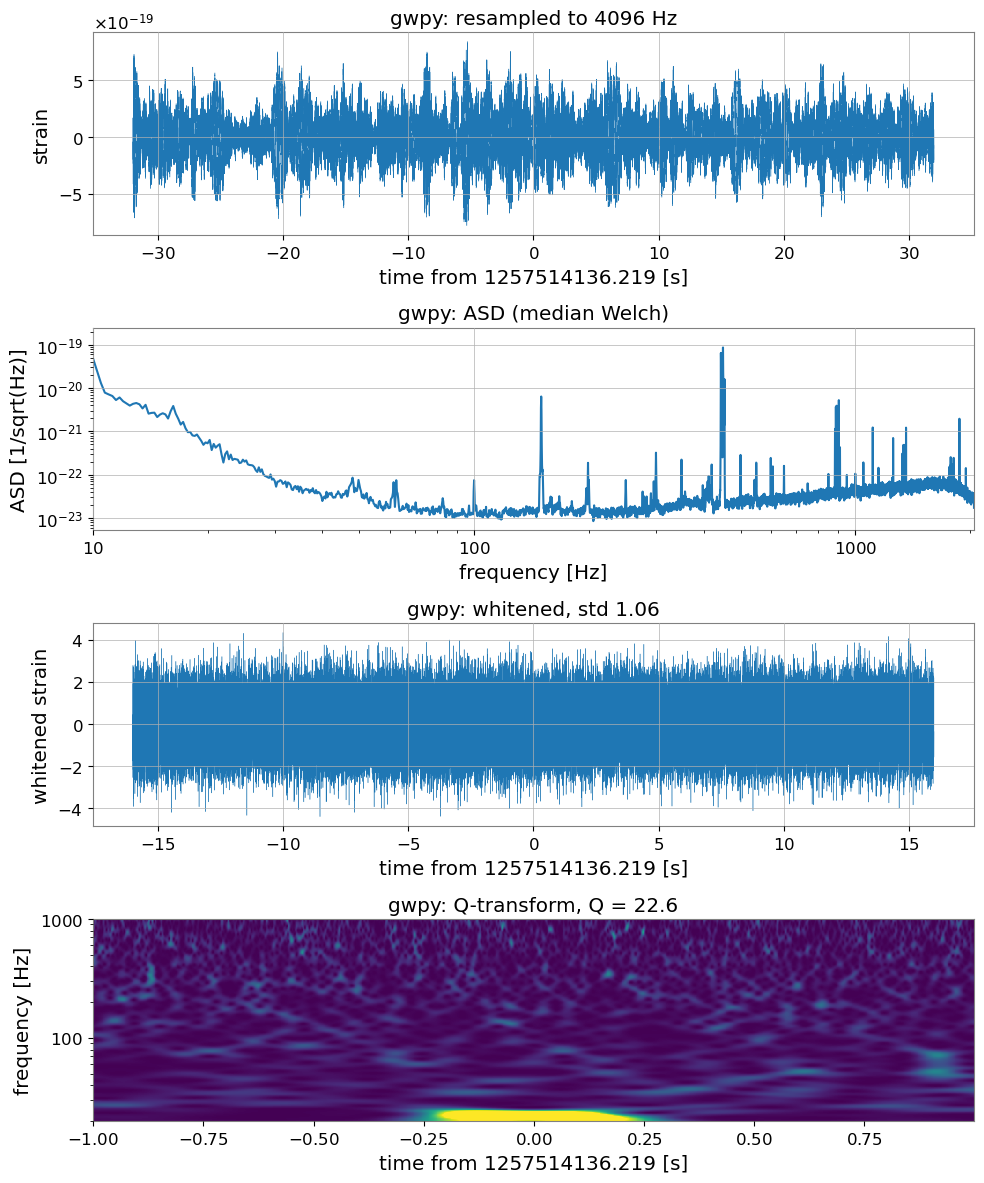

In [20]:
%%time
# gwpy: resample 16 kHz -> 4 kHz, estimate the ASD, whiten, Q-transform; plot each step
data_4k = data.resample(fs)                                          # FIR anti-alias (scipy decimate) + downsample by 4
asd_gwpy = data_4k.asd(fftlength=4)                                 # Welch, 4 s Hann segments (defaults: 50% overlap, median)
white_gwpy = data_4k.whiten(asd=asd_gwpy, highpass=10)               # FIR inverse-spectrum truncation (default 2 s filter)
white_gwpy = white_gwpy.crop(start + dc, end - dc)                   # keep the middle 2 * (dt - dc) s (the whitening corrupts 1 s at each end)
print(white_gwpy.duration)
q_gwpy = white_gwpy.q_transform(whiten=False, frange=(20, 1000), logf=True,
                                gps=t0, outseg=(t0 - 1, t0 + 1))     # defaults: Q 4-64, searched near t0; 1000 x 500 over +/- 1 s

fig, axs = plt.subplots(4, 1, figsize=(10, 12))
axs[0].plot(data_4k.times.value - t0, data_4k.value, lw=0.3)
axs[0].set(xlabel=f"time from {t0} [s]", ylabel="strain", title=f"gwpy: resampled to {fs} Hz")
axs[1].loglog(asd_gwpy.frequencies.value, asd_gwpy.value)
axs[1].set(xlim=(10, fs / 2), xlabel="frequency [Hz]", ylabel="ASD [1/sqrt(Hz)]", title="gwpy: ASD (median Welch)")
axs[2].plot(white_gwpy.times.value - t0, white_gwpy.value, lw=0.3)
axs[2].set(xlabel=f"time from {t0} [s]", ylabel="whitened strain", title=f"gwpy: whitened, std {white_gwpy.value.std():.2f}")
axs[3].pcolormesh(q_gwpy.times.value - t0, q_gwpy.frequencies.value, q_gwpy.value.T, shading="auto", vmin=0, vmax=25)
axs[3].set(yscale="log", xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]", title=f"gwpy: Q-transform, Q = {q_gwpy.q:.1f}")
axs[3].grid(False)
fig.tight_layout()

ASD, SAGE / gwpy over 20-1500 Hz: median 0.9981, range 0.993-1.004
whitened: std SAGE 1.063, gwpy 1.063; correlation 0.9998
Q-transform: Q SAGE 22.6, gwpy 22.6; largest difference 1.8e-03 of gwpy's peak (from the resampling: gwpy's anti-alias filter lets through ~1e3 x more aliasing than SAGE's decimate)


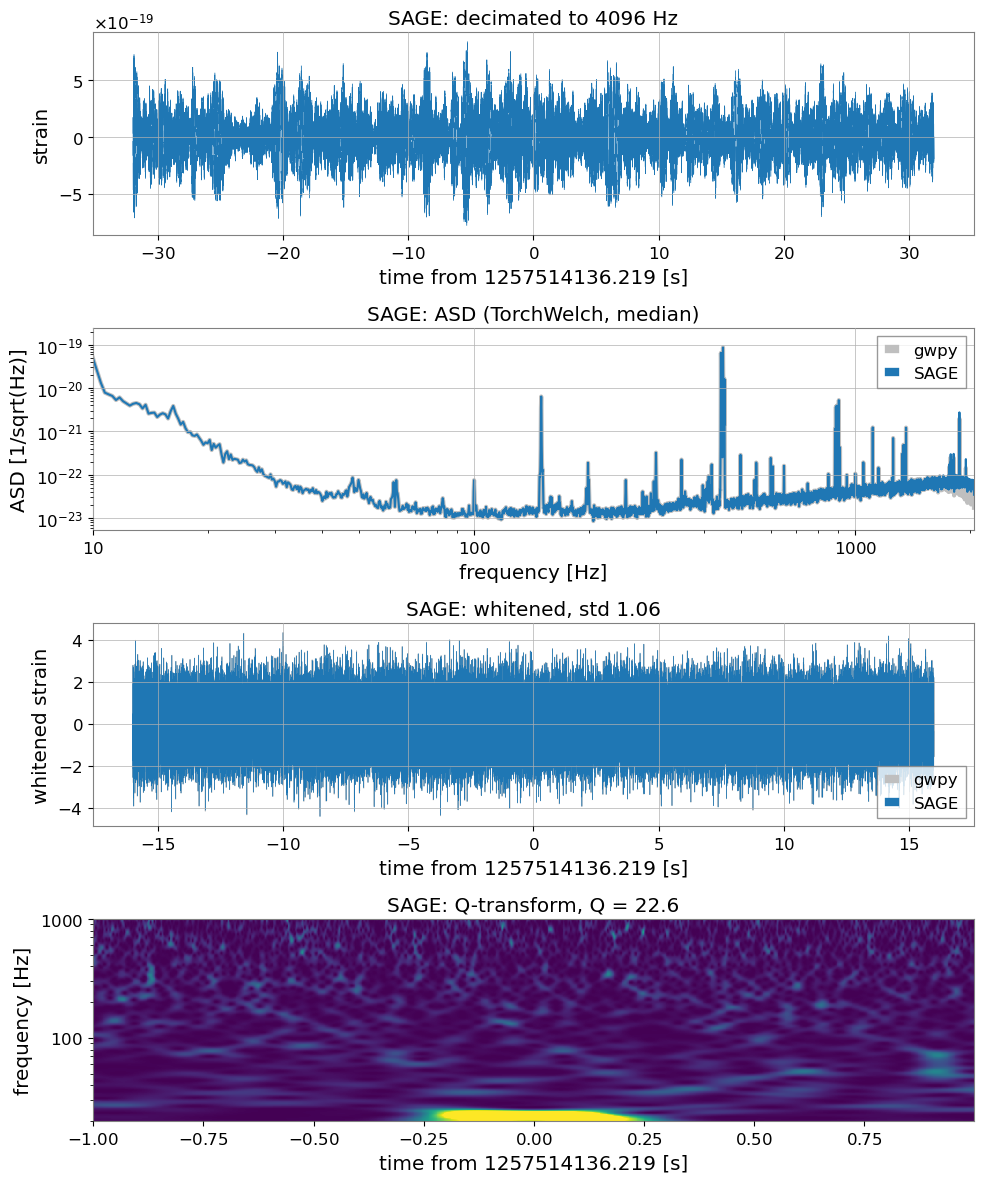

In [21]:
#%%time
# SAGE: the same steps with SAGE's functions (float64 for real strain, see FIRWhitening's docstring);
# gwpy's results from the cell above are drawn in grey for comparison

data_torch = torch.tensor(data.value)
fs_old = int(data.sample_rate.value) # 16 kHz -> 4 kHz
x_sage = decimate(data_torch, fs_old // fs)   # half-band FIR anti-alias, x2 per pass

f_sage, psd_sage = TorchWelch(delta_t=1 / fs, seg_len=4 * fs, seg_stride=2 * fs)(x_sage, return_freqs=True)                         # frequencies (Hz) and PSD
asd_sage = psd_sage.sqrt()
whiten = FIRWhitening(fs, highpass=10.0, dtype=torch.float64)                   # gwpy's whiten (default 2 s filter); float64 for real strain
white_sage = whiten(x_sage.reshape(1, 1, -1), asd_sage[None])[0, 0]             # 1 s shorter at each end
cut = dc * fs - whiten.pad                                                       # then the same crop as gwpy: start + dc to end - dc
white_sage = white_sage[cut:white_sage.numel() - cut]
tc = t0 - (start + dc)                                                           # glitch time, in s from the start of white_sage
qt = QTransform(fs, white_sage.numel(), frange=(20, 1000), logf=True,
                outseg=(tc - 1, tc + 1))                                         # defaults as gwpy: Q 4-64, 1000 x 500 over +/- 1 s
q_sage, q = qt(white_sage, gps=tc, return_q=True)                                # Q searched near the glitch, as gwpy's gps=

t = start - t0 + np.arange(x_sage.numel()) / fs
fig, axs = plt.subplots(4, 1, figsize=(10, 12))
axs[0].plot(t, x_sage, lw=0.3)
axs[0].set(xlabel=f"time from {t0} [s]", ylabel="strain", title=f"SAGE: decimated to {fs} Hz")
axs[1].loglog(asd_gwpy.frequencies.value, asd_gwpy.value, color="0.75", lw=3, label="gwpy")
axs[1].loglog(f_sage, asd_sage, label="SAGE")
axs[1].set(xlim=(10, fs / 2), xlabel="frequency [Hz]", ylabel="ASD [1/sqrt(Hz)]", title="SAGE: ASD (TorchWelch, median)")
axs[1].legend()
axs[2].plot(white_gwpy.times.value - t0, white_gwpy.value, color="0.75", lw=0.6, label="gwpy")
axs[2].plot(t[dc * fs:t.size - dc * fs], white_sage, lw=0.3, label="SAGE")
axs[2].set(xlabel=f"time from {t0} [s]", ylabel="whitened strain", title=f"SAGE: whitened, std {float(white_sage.std()):.2f}")
axs[2].legend()
axs[3].pcolormesh(qt.times - tc, qt.frequencies, q_sage.T, shading="auto", vmin=0, vmax=25)
axs[3].set(yscale="log", xlabel=f"time from {t0} [s]", ylabel="frequency [Hz]", title=f"SAGE: Q-transform, Q = {float(q):.1f}")
axs[3].grid(False)
fig.tight_layout()

# how close to gwpy: only the resampling differs (gwpy/scipy's FIR blocks ~60 dB above 2048 Hz, SAGE's ~92 dB);
# given the same resampled data, the ASD, whitening and Q-transform agree with gwpy to ~1e-6
band = (f_sage >= 20) & (f_sage <= 1500)
ratio = (asd_sage / torch.tensor(asd_gwpy.value))[band]
print(f"ASD, SAGE / gwpy over 20-1500 Hz: median {float(ratio.median()):.4f}, range {float(ratio.min()):.3f}-{float(ratio.max()):.3f}")
print(f"whitened: std SAGE {float(white_sage.std()):.3f}, gwpy {white_gwpy.value.std():.3f}; "
      f"correlation {np.corrcoef(white_sage.numpy(), white_gwpy.value)[0, 1]:.4f}")
print(f"Q-transform: Q SAGE {float(q):.1f}, gwpy {q_gwpy.q:.1f}; largest difference "
      f"{float((q_sage - torch.tensor(q_gwpy.value)).abs().max() / q_gwpy.value.max()):.1e} of gwpy's peak "
      f"(from the resampling: gwpy's anti-alias filter lets through ~1e3 x more aliasing than SAGE's decimate)")

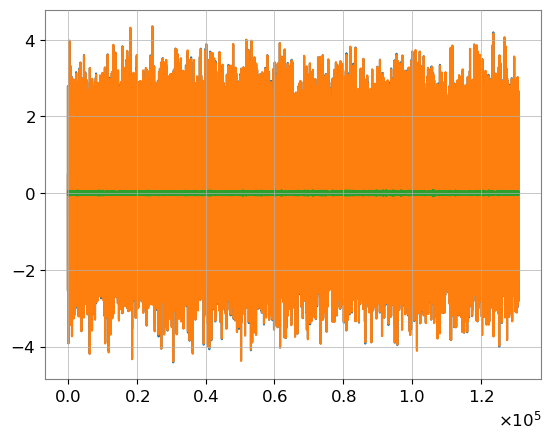

In [22]:

plt.plot(white_sage.numpy())
plt.plot(white_gwpy.value)
plt.plot(white_sage.numpy() - white_gwpy.value)

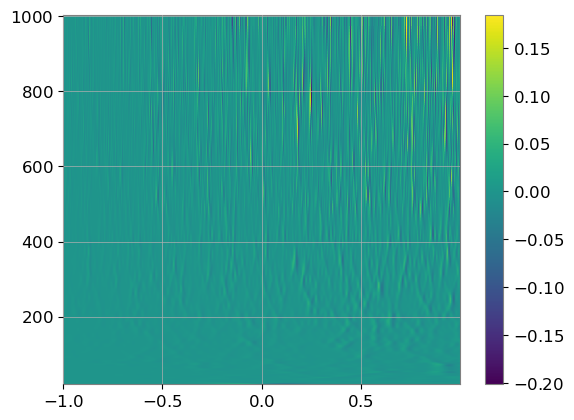

In [23]:
plt.pcolormesh(qt.times - tc, qt.frequencies,  q_gwpy.value.T - q_sage.numpy().T)
plt.colorbar()

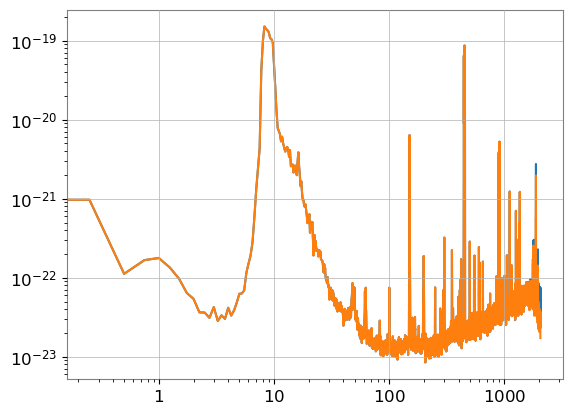

In [24]:
plt.loglog(f_sage.numpy(), asd_sage.numpy())
plt.loglog(asd_gwpy.frequencies, asd_gwpy.value)

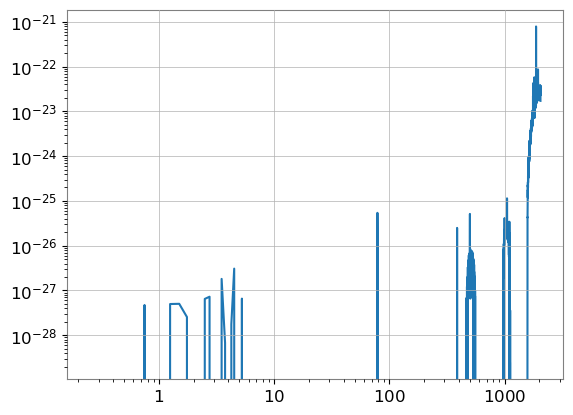

In [25]:
plt.loglog(f_sage.numpy(), asd_sage.numpy() - asd_gwpy.value)